# Project #2
## Binary Classification

**Semester : 2026 Fall**\
**Course : DATA 555 (Fundamentals of Data Science and AI)**\

## 1. Data Analysis And Exploratory Data Analysis (EDA)

In [1]:
!pip install openpyxl

In [2]:
import pandas as pd

df = pd.read_excel('./Data/Pumpkin_Seeds_Dataset.xlsx')

print("Check data type and null")
df.info()
print("\nnumber of each class:\n", df['Class'].value_counts())


Check data type and null
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Area               2500 non-null   int64  
 1   Perimeter          2500 non-null   float64
 2   Major_Axis_Length  2500 non-null   float64
 3   Minor_Axis_Length  2500 non-null   float64
 4   Convex_Area        2500 non-null   int64  
 5   Equiv_Diameter     2500 non-null   float64
 6   Eccentricity       2500 non-null   float64
 7   Solidity           2500 non-null   float64
 8   Extent             2500 non-null   float64
 9   Roundness          2500 non-null   float64
 10  Aspect_Ration      2500 non-null   float64
 11  Compactness        2500 non-null   float64
 12  Class              2500 non-null   object 
dtypes: float64(10), int64(2), object(1)
memory usage: 254.0+ KB

number of each class:
 Class
Çerçevelik       1300
Ürgüp Sivrisi    1200
Name: cou

I chose Kernel Density Estimate (KDE) plots, which overlay density functions, to most intuitively visualize the differences in data characteristics between the two classes (Çerçevelik and Ürgüp Sivrisi). 

Additionally, I used a Correlation Heatmap to examine how the 12 numerical variables relate to one another and to detect the presence of multicollinearity.

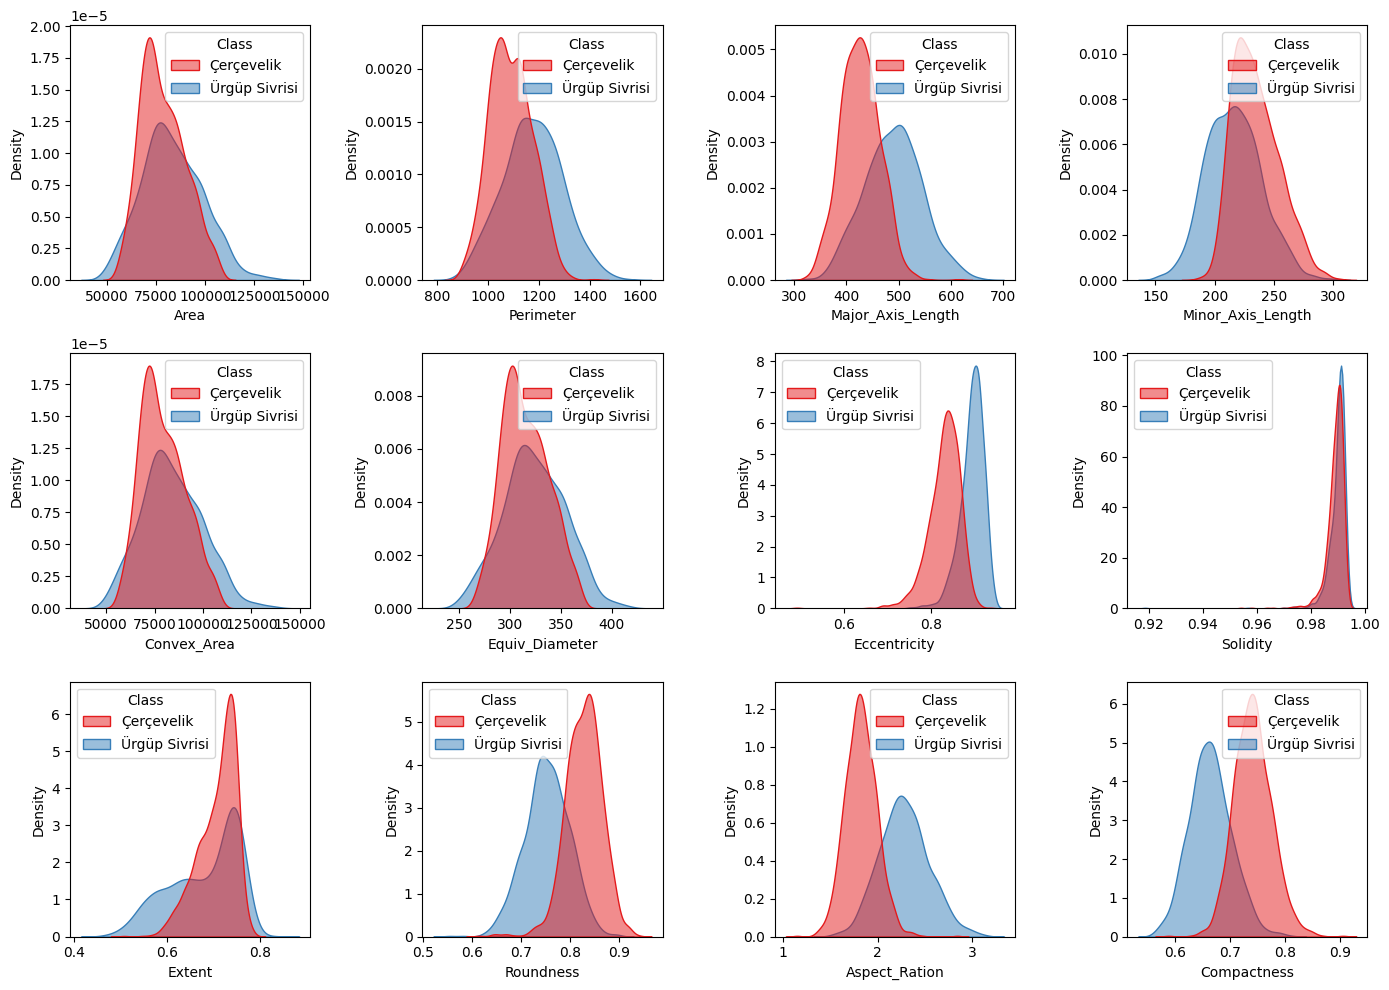

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

features_to_plot = df.select_dtypes(include=['float64', 'int64'])


fig, axes = plt.subplots(3, 4, figsize=(14, 10))
axes = axes.flatten()

for i, feature in enumerate(features_to_plot):
    sns.kdeplot(data=df, x=feature, hue='Class', fill=True, ax=axes[i], alpha=0.5, palette='Set1')
    axes[i].set_xlabel(feature)

plt.tight_layout()
plt.show()

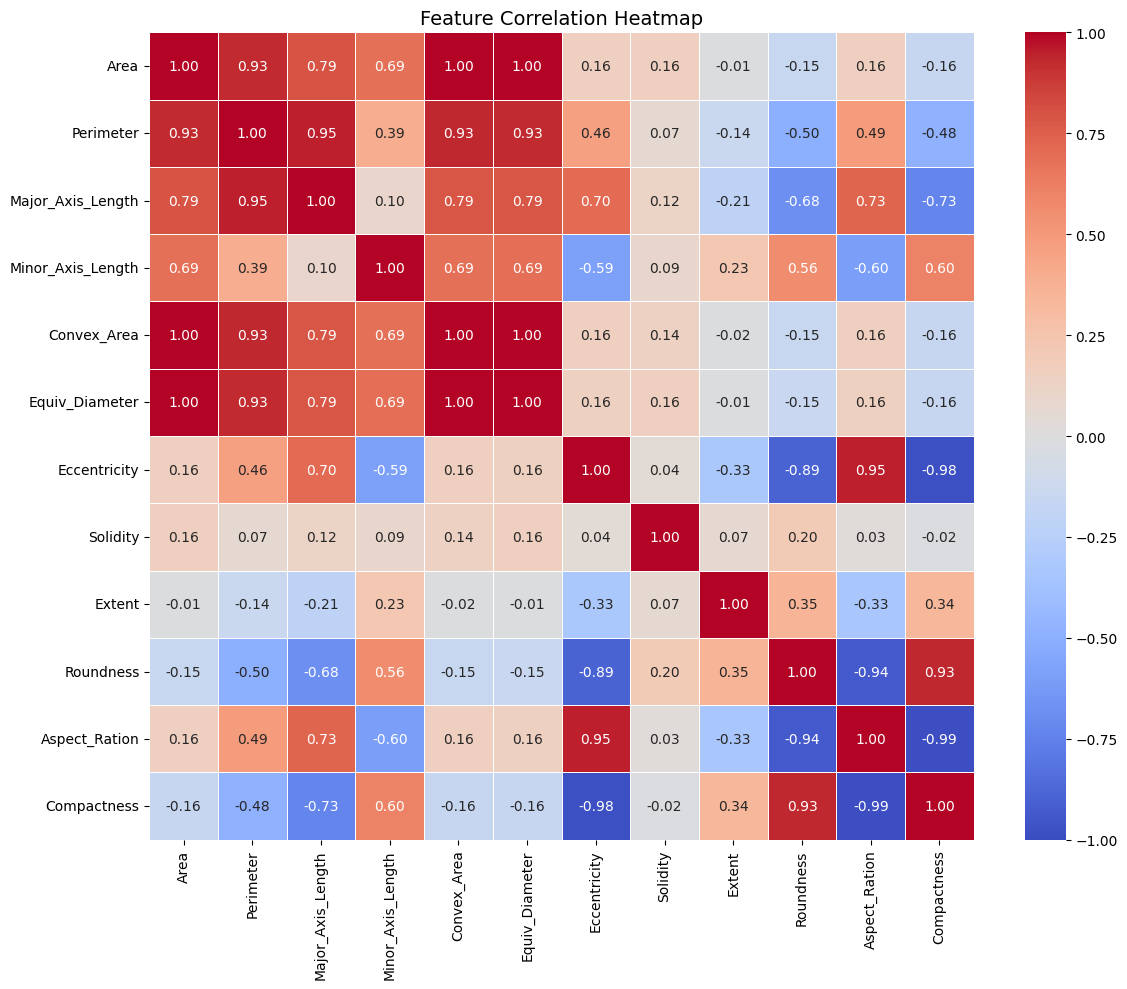

In [6]:
plt.figure(figsize=(12, 10))
numeric_df = df.select_dtypes(include=['float64', 'int64'])
corr_matrix = numeric_df.corr()

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', 
            vmin=-1, vmax=1, linewidths=0.5, annot_kws={"size": 10})
plt.title('Feature Correlation Heatmap', fontsize=14)
plt.tight_layout()
plt.show()

The KDE plots reveal clear distinctions between the classes in aspect_ratio, compactness, eccentricity, and major_axis_length. 

The heatmap shows that variables such as Area, Perimeter, Convex_Area, and Equiv_Diameter exhibit very strong positive correlations, with coefficients of 0.99 or higher. This indicates that these features provide overlapping information, suggesting that Feature Selection will be necessary for future model improvements.

## 2. Split Dataset into Training and Testing Set

In [7]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

X = df.drop('Class', axis=1)
y = df['Class']

# label encoding (Çerçevelik=0, Ürgüp Sivrisi=1)
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# split train and test. 
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

## 3. Model Training and Evaluation

In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

base_model = LogisticRegression(random_state=42)
base_model.fit(X_train_scaled, y_train)

y_pred_base = base_model.predict(X_test_scaled)
print(f"Accuracy : {accuracy_score(y_test, y_pred_base):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_base):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_base):.4f}")
print(f"F1 Score : {f1_score(y_test, y_pred_base):.4f}")

Accuracy : 0.8620
Precision: 0.8800
Recall   : 0.8250
F1 Score : 0.8516


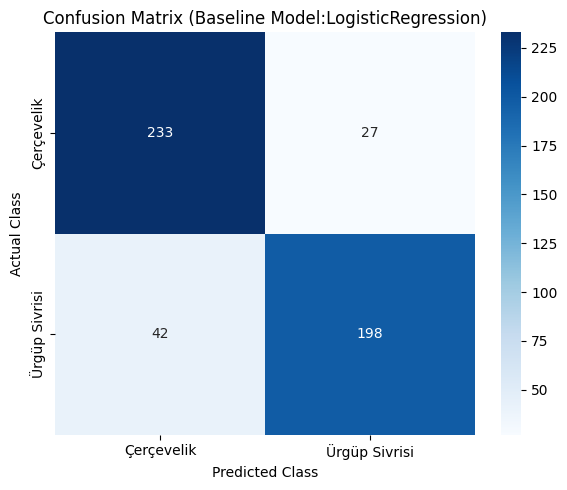

In [9]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns


cm = confusion_matrix(y_test, y_pred_base)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix (Baseline Model:LogisticRegression)')
plt.ylabel('Actual Class')
plt.xlabel('Predicted Class')
plt.tight_layout()
plt.show()

The baseline logistic regression model demonstrated solid performance, achieving approximately 86.2% accuracy and an F1 score of 0.85. However, its reliance on a linear decision boundary limits its ability to learn complex non-linear patterns, and strong multicollinearity among variables risks distorting the model's weights.

To address these limitations, I will select 8 statistically significant features and perform hyperparameter tuning. Additionally, I will adopt a tree-based ensemble model (e.g., Random Forest). Random Forest model is well-suited for non-linear data. So I selected it as an alternative model, utilizing the selected features and tuning its hyperparameters to achieve optimal performance.

# 4. Hyperparameter Tuning And Alternative Model
## 4-1. Feature Selection

In [10]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

selector = SelectKBest(score_func=f_classif, k=8)
X_train_fs = selector.fit_transform(X_train_scaled, y_train)
X_test_fs = selector.transform(X_test_scaled)

selected_features = X.columns[selector.get_support()]
print("Selected Features:", selected_features.tolist())

Selected Features: ['Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length', 'Eccentricity', 'Extent', 'Roundness', 'Aspect_Ration', 'Compactness']


In [11]:
fs_model = LogisticRegression(random_state=42)
fs_model.fit(X_train_scaled, y_train)

y_pred_fs = fs_model.predict(X_test_scaled)
print(f"Accuracy : {accuracy_score(y_test, y_pred_fs):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_fs):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_fs):.4f}")
print(f"F1 Score : {f1_score(y_test, y_pred_fs):.4f}")

Accuracy : 0.8620
Precision: 0.8800
Recall   : 0.8250
F1 Score : 0.8516


## 4-2. Hyperparameter Tunning

In [12]:
log_reg = LogisticRegression(solver='saga', max_iter=10000, random_state=42)

param_grid = [
    {
        'penalty': ['l1', 'l2'], 
        'C': [0.01, 0.1, 1, 10, 100]  
    },
    {
        'penalty': ['elasticnet'], 
        'C': [0.01, 0.1, 1, 10, 100],
        'l1_ratio': [0.2, 0.5, 0.8]   
    }
]

grid_search = GridSearchCV(
    estimator=log_reg, 
    param_grid=param_grid, 
    scoring='accuracy', 
    cv=5,               
    n_jobs=-1           
)

grid_search.fit(X_train_fs, y_train)
print(f"best: {grid_search.best_params_}")

ht_model = grid_search.best_estimator_
y_pred_ht = ht_model.predict(X_test_fs)
print(f"Accuracy : {accuracy_score(y_test, y_pred_ht):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_ht):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_ht):.4f}")
print(f"F1 Score : {f1_score(y_test, y_pred_ht):.4f}")

best: {'C': 1, 'l1_ratio': 0.8, 'penalty': 'elasticnet'}
Accuracy : 0.8620
Precision: 0.8834
Recall   : 0.8208
F1 Score : 0.8510


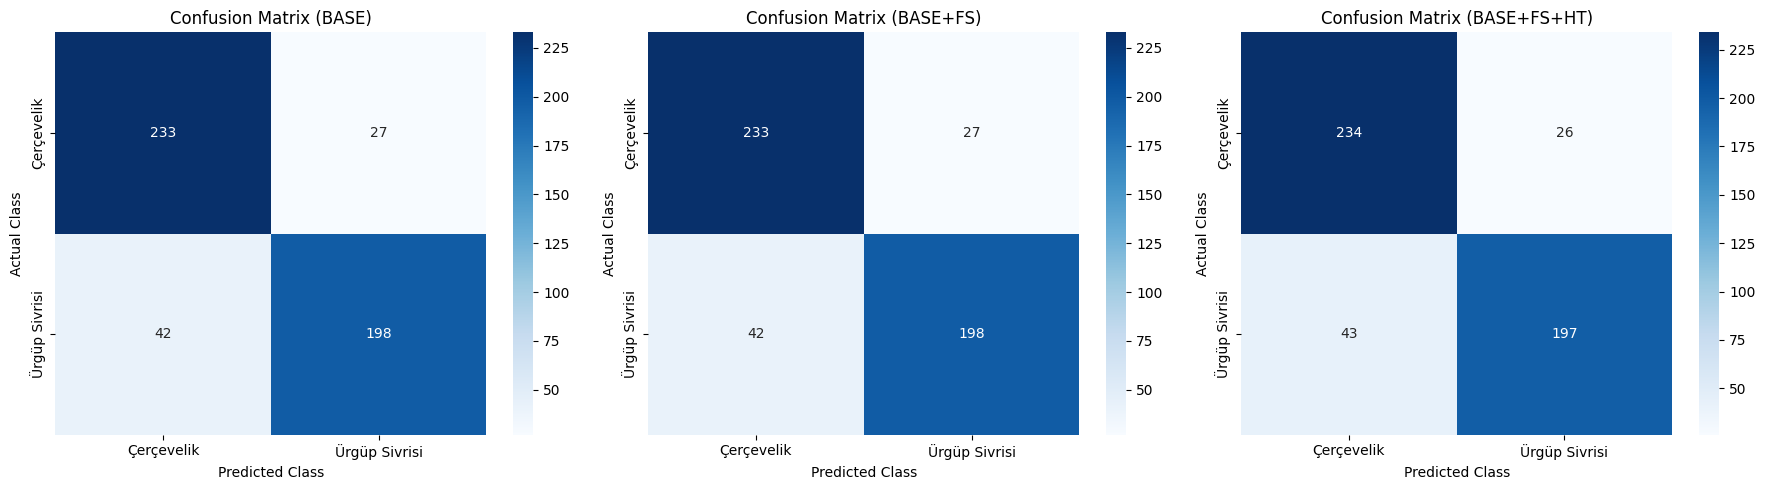

In [13]:
cm1 = confusion_matrix(y_test, y_pred_base)
cm2 = confusion_matrix(y_test, y_pred_fs)
cm3 = confusion_matrix(y_test, y_pred_ht)

cm_list = [cm1, cm2, cm3]
titles = ['BASE', 'BASE+FS', 'BASE+FS+HT'] 

fig, axes = plt.subplots(1, 3, figsize=(18, 5)) 

for i, ax in enumerate(axes):
    sns.heatmap(cm_list[i], annot=True, fmt='d', cmap='Blues', 
                xticklabels=le.classes_, yticklabels=le.classes_, ax=ax)
    
    ax.set_title(f'Confusion Matrix ({titles[i]})')
    ax.set_ylabel('Actual Class')
    ax.set_xlabel('Predicted Class')

plt.tight_layout()
plt.show()

I applied SelectKBest to the logistic regression model to remove noise features that contributed little to distinguishing the target class (selecting 8 features) and attempted to improve performance through hyperparameter tuning. However, due to the inherent limitations of linear-based classification, no performance improvement was achieved.


## 4-3. Alternative Model (RandomForest)

In [14]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

rf = RandomForestClassifier(random_state=42)
param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5]
}

grid = GridSearchCV(rf, param_grid, cv=5, scoring='f1', n_jobs=-1)
grid.fit(X_train_fs, y_train)

print(f"Best Parameters: {grid.best_params_}")

best_model = grid.best_estimator_

y_pred_imp = best_model.predict(X_test_fs)
print(f"\n[Alternative Model Performance]")
print(f"Accuracy : {accuracy_score(y_test, y_pred_imp):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_imp):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_imp):.4f}")
print(f"F1 Score : {f1_score(y_test, y_pred_imp):.4f}")


Best Parameters: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 50}

[Alternative Model Performance]
Accuracy : 0.8880
Precision: 0.9182
Recall   : 0.8417
F1 Score : 0.8783


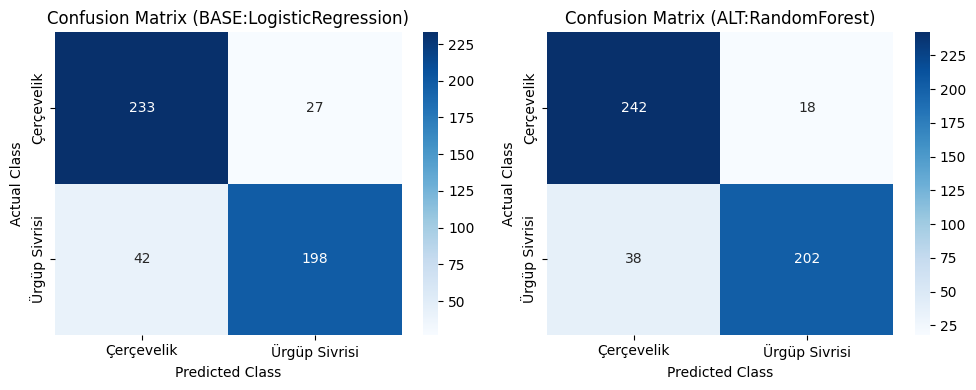

In [15]:
cm1 = confusion_matrix(y_test, y_pred_base)
cm2 = confusion_matrix(y_test, y_pred_imp)

cm_list = [cm1, cm2]
titles = ['BASE:LogisticRegression', 'ALT:RandomForest'] 

fig, axes = plt.subplots(1, 2, figsize=(10, 4)) 

for i, ax in enumerate(axes):
    sns.heatmap(cm_list[i], annot=True, fmt='d', cmap='Blues', 
                xticklabels=le.classes_, yticklabels=le.classes_, ax=ax)
    
    ax.set_title(f'Confusion Matrix ({titles[i]})')
    ax.set_ylabel('Actual Class')
    ax.set_xlabel('Predicted Class')

plt.tight_layout()
plt.show()

As an alternative, I selected a tree-based RandomForestClassifier, which is capable of learning non-linear patterns. By optimizing the depth and number of trees (max_depth=None, min_samples_split=5, n_estimators=50) using GridSearchCV, the prediction accuracy increased from approximately 86.2% to 88.8%, and the F1 score rose from 0.851 to 0.878.

With the reduced complexity of the data the model needed to learn and the application of optimal parameters, I ultimately built a more robust model with improvements in both precision and recall.